[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L8/BA_L8_recal/BA_L8_recal.ipynb)

# BA_L8_recal: Breach rate and loss after correcting VaR forecasts

*Quantlet of Lecture 8, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

VaR 1% breach rates and change of the mean quantile score after correcting six Bitcoin VaR models (HS, EWMA-N, GARCH-t, quantile regression, quantile trees, optionally Chronos-2) by the empirical quantile of their 500 forecast errors before 2024, with intensity Raw, Half or Full. EODHD daily Bitcoin data, test period 1 January 2024 - 23 October 2026.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

Left: VaR 1% breach rates of the Raw, Half and Full forecasts of each model against the 1% target. Right: change of the mean quantile score (QS)
against Raw ($\times 10^{-3}$); positive = worse.
**How to read it**: the same correction moves breach rates in both directions; whether it helps depends on whether the bias of the calibration
period persists into the test period.

In [5]:
# the slide charts use 10-point text and an 8-point legend
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10})
SLIDE_GOLD = '#B8860B'

END = pd.Timestamp('2026-10-23')                       # last day of the lecture sample
btc = pd.read_csv(data_file('market', 'BTC-USD.CC.csv'), parse_dates=['date']).set_index('date').loc[:END]
r = (100 * np.log(btc['close'])).diff().dropna().loc['2015-01-01':]           # daily log return, %
lv = np.log(btc['volume'].replace(0, np.nan)).diff().reindex(r.index).fillna(0)  # daily change of log volume
print(f'Bitcoin daily log returns: {len(r)} days, {r.index[0].date()} to {r.index[-1].date()}')

Bitcoin daily log returns: 4314 days, 2015-01-01 to 2026-10-23


## Data and the six Value-at-Risk models

Daily Bitcoin closes and volumes from EODHD (course repository, `data/market`), to 23 October 2026; daily log returns in per cent.
Each model forecasts $q_t$, the $\alpha$-quantile of $r_t$ given information up to day $t-1$ (a negative return); the one-day
Value-at-Risk (VaR) at level $\alpha$ is $\mathrm{VaR}_t = -q_t$, a positive loss in % ("VaR 1%" is minus the 1% quantile).

* historical simulation (HS): the empirical $\alpha$-quantile of the last 500 returns;
* EWMA-N, an exponentially weighted moving average of squared returns with a Normal quantile: $\sigma_t^2 = 0.94\,\sigma_{t-1}^2 + 0.06\, r_{t-1}^2$, $q_t = \Phi^{-1}(\alpha)\sigma_t$;
* GARCH(1,1)-t, a generalised autoregressive conditional heteroskedasticity model with Student-$t$ errors,
  $q_t = \mu + \sigma_t\, t_\nu^{-1}(\alpha)\sqrt{(\nu-2)/\nu}$, refitted every 21 days on all data since 2015;
* QReg, linear quantile regression (Koenker and Bassett, 1978) on heterogeneous autoregressive (HAR) volatility terms,
  $q_t = \beta_0 + \beta_1 |r_{t-1}| + \beta_2 \mathrm{RV}^{(5)}_{t-1} + \beta_3 \mathrm{RV}^{(22)}_{t-1} + \beta_4 \mathrm{RV}^{(66)}_{t-1} + \beta_5 \min(r_{t-1},0)$,
  with $\mathrm{RV}^{(k)}$ the $k$-day root mean square return; rolling 1,500 days, refitted every 21 days;
* QGBM, gradient-boosted quantile trees: 300 trees minimising the quantile loss on 9 features (returns, volatilities, volume change);
  rolling 1,500 days, refitted every 63 days;
* Chronos-2, a pretrained transformer forecasting model used zero-shot on the last 512 daily returns (optional, see below).

Forecasts start on 1 June 2022; the test period is 1 January 2024 – 23 October 2026.

In [6]:
from scipy import stats
import statsmodels.api as sm
from sklearn.ensemble import GradientBoostingRegressor
from arch import arch_model

ALPHAS = [0.01, 0.05]
F0, TT0 = pd.Timestamp('2022-06-01'), pd.Timestamp('2024-01-01')
CHRONOS_RELEASE = pd.Timestamp('2025-10-20')
NCAL = 500
n = len(r); vdates = r.index; R = r.values
fidx = np.where(vdates >= F0)[0]               # the forecast for day i uses data up to day i-1

# features known at the close of day t (to forecast t+1)
XQ = pd.DataFrame({'r0': r, 'r1': r.shift(1), 'r2': r.shift(2), 'a0': r.abs(),
                   'rv5': np.sqrt((r ** 2).rolling(5).mean()), 'rv22': np.sqrt((r ** 2).rolling(22).mean()),
                   'rv66': np.sqrt((r ** 2).rolling(66).mean()), 'dv': lv, 'neg': np.minimum(r, 0)}).values
Q = {m: {a: np.full(n, np.nan) for a in ALPHAS} for m in ['HS', 'EWMA-N', 'GARCH-t', 'QReg', 'QGBM']}

# HS and EWMA-N
s2 = np.var(R[:250]); ew = np.empty(n)
for i in range(n):
    ew[i] = s2                                  # variance forecast for day i from data up to i-1
    s2 = 0.94 * s2 + 0.06 * R[i] ** 2
for i in fidx:
    for a in ALPHAS:
        Q['HS'][a][i] = np.quantile(R[i - 500:i], a)
        Q['EWMA-N'][a][i] = stats.norm.ppf(a) * np.sqrt(ew[i])

# GARCH(1,1)-t, refitted every 21 days, parameters fixed within the block
for b0 in range(fidx[0], n, 21):
    b1 = min(b0 + 21, n)
    fit = arch_model(R[:b1], mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(last_obs=b0, disp='off')
    fc = fit.forecast(start=b0 - 1, horizon=1, reindex=False)
    mu, var = fc.mean.values[:, 0], fc.variance.values[:, 0]
    nu = fit.params['nu']
    for a in ALPHAS:
        Q['GARCH-t'][a][b0:b1] = mu[:b1 - b0] + stats.t.ppf(a, nu) * np.sqrt((nu - 2) / nu) * np.sqrt(var[:b1 - b0])

# quantile regression (HAR terms) and gradient-boosted quantile trees, rolling 1500 days
QR_COLS = [3, 4, 5, 6, 8]                       # |r|, RV5, RV22, RV66, min(r, 0)
for b0 in range(fidx[0], n, 21):
    b1 = min(b0 + 21, n)
    tr = np.arange(max(66, b0 - 1500), b0 - 1)  # feature row j predicts R[j+1]
    for a in ALPHAS:
        qr = sm.QuantReg(R[tr + 1], sm.add_constant(XQ[tr][:, QR_COLS])).fit(q=a, max_iter=5000)
        Q['QReg'][a][b0:b1] = sm.add_constant(XQ[b0 - 1:b1 - 1][:, QR_COLS], has_constant='add') @ qr.params
    if (b0 - fidx[0]) % 63 == 0:
        gb = {a: GradientBoostingRegressor(loss='quantile', alpha=a, n_estimators=300, max_depth=3, learning_rate=0.03,
                                           min_samples_leaf=20, subsample=0.8, random_state=1).fit(XQ[tr], R[tr + 1]) for a in ALPHAS}
    for a in ALPHAS:
        Q['QGBM'][a][b0:b1] = gb[a].predict(XQ[b0 - 1:b1 - 1])
print(f'Forecasts from {vdates[fidx[0]].date()} to {vdates[-1].date()} for', ', '.join(Q))

Forecasts from 2022-06-01 to 2026-10-23 for HS, EWMA-N, GARCH-t, QReg, QGBM


### The pretrained model (optional)

Chronos-2 needs PyTorch and the `chronos-forecasting` package and downloads the model weights (several hundred MB) from Hugging Face,
so it is switched off: with `RUN_CHRONOS = False` the notebook covers the five other models. The slide chart and the Chronos-2 numbers on the
slides come from a run with `RUN_CHRONOS = True`; set it to `True` and run the notebook again to reproduce them.
The checkpoint is pinned: Hugging Face model `amazon/chronos-2`, revision `29ec3766d36d6f73f0696f85560a422f50e8498c`, with `chronos-forecasting` 2.3.2.

In [7]:
RUN_CHRONOS = False

if RUN_CHRONOS:
    import importlib, subprocess, sys
    try:
        importlib.import_module('chronos')
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'chronos-forecasting==2.3.2'], check=True)
    import torch
    from chronos import Chronos2Pipeline
    CHRONOS_REV = '29ec3766d36d6f73f0696f85560a422f50e8498c'                   # pinned checkpoint of amazon/chronos-2
    pipe = Chronos2Pipeline.from_pretrained('amazon/chronos-2', revision=CHRONOS_REV, device_map='cpu')
    Q['Chronos-2'] = {a: np.full(n, np.nan) for a in ALPHAS}
    for k in range(0, len(fidx), 128):
        ii = fidx[k:k + 128]
        ctx = [torch.tensor(R[i - 512:i], dtype=torch.float32) for i in ii]       # context: the last 512 daily returns
        qq, _ = pipe.predict_quantiles(ctx, prediction_length=1, quantile_levels=ALPHAS)
        for j, i in enumerate(ii):
            for cc, a in enumerate(ALPHAS):
                Q['Chronos-2'][a][i] = float(qq[j][0, 0, cc])
VMODELS = list(Q)
tt = np.where((vdates >= TT0) & (vdates <= END))[0]
y = R[tt]; dd = vdates[tt]
print('Models:', ', '.join(VMODELS), f'| test period {dd[0].date()} to {dd[-1].date()}, T = {len(tt)} days')

Models: HS, EWMA-N, GARCH-t, QReg, QGBM | test period 2024-01-01 to 2026-10-23, T = 1027 days


## The correction

Forecast errors $e_t = r_t - q_t$. The static correction $\hat c$ is the empirical $\alpha$-quantile of the 500 errors before 1 January 2024;
the corrected forecast is $q_t + \lambda\hat c$ with $\lambda = 0$ (Raw), $\tfrac12$ (Half), $1$ (Full). The rolling Full correction refits
$\hat c$ every day on the last 500 errors. The standard error $\widehat{\mathrm{se}}$ of $\hat c$ comes from a block bootstrap (2,000 resamples,
blocks of 20 days); $\hat c^2/\widehat{\mathrm{se}}^2$ estimates $\delta^2/\sigma_Q^2$. DM p-values compare Half and Full with Raw.

Chronos-2 on the slides (run with `RUN_CHRONOS = True`), VaR 1%: $\hat c = 0.33$, $\hat c^2/\widehat{\mathrm{se}}^2 = 0.05$;
breach rates 1.27% (Raw), 1.36% (Half), 1.36% (Full); mean QS 0.0827, 0.0833, 0.0839.
This step takes about a minute.

In [8]:
def qs(y, q, a):
    """Quantile score (pinball loss)."""
    u = y - q
    return u * (a - (u < 0))


def kupiec(h, a):
    """Kupiec likelihood-ratio test of the breach rate: statistic and p-value."""
    T, x = len(h), int(h.sum())
    p = x / T
    ll0 = (T - x) * np.log(1 - a) + x * np.log(a)
    ll1 = (T - x) * np.log(1 - p) + (x * np.log(p) if x > 0 else 0)
    return 2 * (ll1 - ll0), stats.chi2.sf(2 * (ll1 - ll0), 1)


def christ(h):
    """Christoffersen test of independence of breaches: p-value."""
    h = h.astype(int)
    n00 = ((h[:-1] == 0) & (h[1:] == 0)).sum(); n01 = ((h[:-1] == 0) & (h[1:] == 1)).sum()
    n10 = ((h[:-1] == 1) & (h[1:] == 0)).sum(); n11 = ((h[:-1] == 1) & (h[1:] == 1)).sum()
    p01, p11, p = n01 / (n00 + n01), (n11 / (n10 + n11) if n10 + n11 else 0), (n01 + n11) / (n00 + n01 + n10 + n11)
    L = lambda x, k: (k * np.log(x) if k else 0)
    ll1 = L(1 - p01, n00) + L(p01, n01) + L(1 - p11, n10) + L(p11, n11)
    ll0 = L(1 - p, n00 + n10) + L(p, n01 + n11)
    return stats.chi2.sf(2 * (ll1 - ll0), 1)


def dm(dl, lag=None):
    """Diebold-Mariano test with a Newey-West long-run variance: statistic and two-sided p-value."""
    T = len(dl); lag = lag or int(np.floor(4 * (T / 100) ** (2 / 9)))
    u = dl - dl.mean()
    lrv = u @ u / T + 2 * sum((1 - k / (lag + 1)) * (u[k:] @ u[:-k]) / T for k in range(1, lag + 1))
    t = dl.mean() / np.sqrt(lrv / T)
    return t, 2 * stats.norm.sf(abs(t))


def bboot_se(e, a, B=2000, L=20, seed=7):
    """Block-bootstrap standard error of the empirical a-quantile."""
    rng = np.random.default_rng(seed); T = len(e); out = []
    for _ in range(B):
        st = rng.integers(0, T, int(np.ceil(T / L)))
        idx = (st[:, None] + np.arange(L)[None]).ravel()[:T] % T
        out.append(np.quantile(e[idx], a))
    return np.std(out, ddof=1)


it0 = tt[0]
REC = {}
for a in ALPHAS:
    for m in VMODELS:
        q = Q[m][a][tt]; l = qs(y, q, a)
        e_cal = R[it0 - NCAL:it0] - Q[m][a][it0 - NCAL:it0]
        cst = np.quantile(e_cal, a)
        se = bboot_se(e_cal, a)
        roll = np.array([np.quantile(R[i - NCAL:i] - Q[m][a][i - NCAL:i], a) for i in tt])
        row = {'c_hat': cst, 'c_hat^2/se^2': cst ** 2 / se ** 2}
        for nm, adj in [('Raw', 0), ('Half', 0.5 * cst), ('Full', cst), ('Full rolling', roll)]:
            row[f'breach % {nm}'] = 100 * (y < q + adj).mean()
            row[f'QS {nm}'] = qs(y, q + adj, a).mean()
        for nm, adj in [('Half', 0.5 * cst), ('Full', cst)]:
            row[f'DM p {nm} vs Raw'] = dm(qs(y, q + adj, a) - l)[1]
        REC[(m, a)] = row
REC = pd.DataFrame(REC).T
for a in ALPHAS:
    print(f'\nVaR {100 * a:.0f}%, static correction fitted on the 500 errors before 2024 (breach rate in %, QS = mean quantile score):')
    print(REC.xs(a, level=1).round(4).to_string())


VaR 1%, static correction fitted on the 500 errors before 2024 (breach rate in %, QS = mean quantile score):
          c_hat  c_hat^2/se^2  breach % Raw  QS Raw  breach % Half  QS Half  breach % Full  QS Full  breach % Full rolling  QS Full rolling  DM p Half vs Raw  DM p Full vs Raw
HS       1.9112        2.1821        1.1685  0.0842         2.0448   0.0893         3.2132   0.1058                 1.5579           0.0908            0.1758            0.0087
EWMA-N  -1.1419        0.3573        2.1422  0.0880         1.6553   0.0831         0.9737   0.0816                 1.4606           0.0822            0.0474            0.1450
GARCH-t -0.0632        0.0010        0.6816  0.0803         0.6816   0.0804         0.6816   0.0805                 1.2658           0.0804            0.2053            0.2053
QReg     0.6322        0.5666        0.8763  0.0822         0.9737   0.0821         0.9737   0.0820                 1.1685           0.0835            0.9138            0.9249
QGBM     0

## The chart

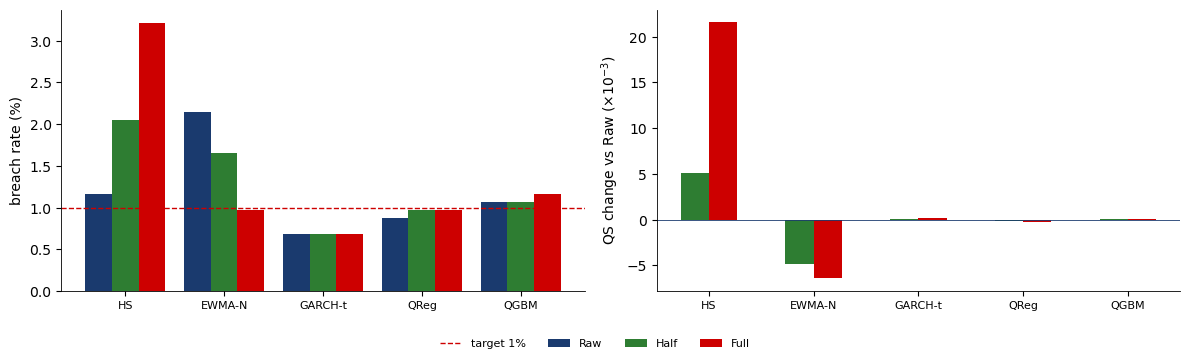

In [9]:
r1 = REC.xs(0.01, level=1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
w = 0.27
x = np.arange(len(VMODELS))
for k, (nm, col) in enumerate([('Raw', BLUE), ('Half', GREEN), ('Full', RED)]):
    ax[0].bar(x + (k - 1) * w, r1.loc[VMODELS, f'breach % {nm}'], w, color=col, label=nm)
    if nm != 'Raw':
        ax[1].bar(x + (k - 1.5) * w, 1000 * (r1.loc[VMODELS, f'QS {nm}'] - r1.loc[VMODELS, 'QS Raw']), w, color=col)
ax[0].axhline(1, color=RED, ls='--', lw=1.0, label='target 1%')
ax[1].axhline(0, color=BLUE, lw=0.6)
ax[0].set_ylabel('breach rate (%)'); ax[1].set_ylabel(r'QS change vs Raw ($\times 10^{-3}$)')
for k_ in range(2):
    ax[k_].set_xticks(x); ax[k_].set_xticklabels(VMODELS, fontsize=8)
fig.legend(loc='lower center', ncol=4, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_fig(fig, 'ba_l8_recal')